# CS 320 | YAMNet Sound Classification Evaluation

**Project:** Encore: Music from Everyday Sounds

**Objective:** Evaluate YAMNet's ability to classify everyday sounds and determine whether its predictions are useful for assigning musical roles in beat generation.

**Dataset:** 31 original smartphone recordings across 10 sound categories, including repeated recordings, short sounds, and one mixed-sound recording.

## 1. Dataset Extraction & Audio Preprocessing

**Purpose:** Prepare smartphone recordings for YAMNet classification.

- **Original format:** M4A (AAC)
- **Required format:** WAV, 16 kHz, mono
- **Dataset:** 31 recordings across 10 everyday sound categories
- **Preprocessing tool:** FFmpeg

The recordings are extracted from a ZIP archive and converted into YAMNet-compatible audio without modifying the original files.

### Running the Notebook

This notebook was developed and tested in Google Colab.

1. Upload the original `Recordings - CS320-20261025T132155Z-1-001.zip` archive to `/content/` in Colab. (In Wren - it is under YAMNet Recordings)
2. Run the ZIP extraction cell to extract the original M4A recordings.
3. Run the FFmpeg preprocessing cell to convert the recordings to 16 kHz mono WAV files.
4. Run the YAMNet model setup cells to load the pretrained model and class labels.
5. Run the individual validation and batch classification cells.
6. Run the CSV export cell to save the classification results.

The notebook requires TensorFlow, TensorFlow Hub, NumPy, SciPy, Matplotlib, and FFmpeg. These were available in the Colab environment used for testing.

The audio archive must be provided separately because it is not embedded in the notebook. The saved notebook outputs and CSV can be inspected without rerunning inference.

In [3]:
!unzip -oq "/content/Recordings - CS320-20261025T132155Z-1-001.zip" -d "/content/yamnet_recordings"

In [4]:
%%bash
mkdir -p "/content/yamnet_recordings/wav"

for file in "/content/yamnet_recordings/Recordings - CS320/"*.m4a; do
    name="$(basename "$file" .m4a)"
    ffmpeg -nostdin -hide_banner -loglevel error -y -i "$file" -ac 1 -ar 16000 "/content/yamnet_recordings/wav/${name}.wav" || exit 1
done

echo "Converted $(find /content/yamnet_recordings/wav -maxdepth 1 -name '*.wav' | wc -l) files."

Converted 31 files.


##### Copyright 2020 The TensorFlow Hub Authors.

Licensed under the Apache License, Version 2.0 (the "License");

In [5]:
#@title Copyright 2020 The TensorFlow Hub Authors. All Rights Reserved.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
# ==============================================================================

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://www.tensorflow.org/hub/tutorials/yamnet"><img src="https://www.tensorflow.org/images/tf_logo_32px.png" />View on TensorFlow.org</a>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/hub/tutorials/yamnet.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/docs/blob/master/site/en/hub/tutorials/yamnet.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View on GitHub</a>
  </td>
  <td>
    <a href="https://storage.googleapis.com/tensorflow_docs/docs/site/en/hub/tutorials/yamnet.ipynb"><img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
  <td>
    <a href="https://tfhub.dev/google/yamnet/1"><img src="https://www.tensorflow.org/images/hub_logo_32px.png" />See TF Hub model</a>
  </td>
</table>

# Sound classification with YAMNet

YAMNet is a deep net that predicts 521 audio event [classes](https://github.com/tensorflow/models/blob/master/research/audioset/yamnet/yamnet_class_map.csv) from the [AudioSet-YouTube corpus](http://g.co/audioset) it was trained on. It employs the
[Mobilenet_v1](https://arxiv.org/pdf/1704.04861.pdf) depthwise-separable
convolution architecture.

## 2. YAMNet Model Setup

**Purpose:** Initialize the pretrained YAMNet model and prepare its sound classification labels.

- **Model:** YAMNet (MobileNetV1-based architecture)
- **Framework:** TensorFlow and TensorFlow Hub
- **Output:** Classification scores across 521 sound classes
- **Input:** Mono audio sampled at 16 kHz

This section uses the official TensorFlow YAMNet tutorial implementation.

In [6]:
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import csv

import matplotlib.pyplot as plt
from IPython.display import Audio
from scipy.io import wavfile
import scipy.signal

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Load the Model from TensorFlow Hub.

Note: to read the documentation just follow the model's [url](https://tfhub.dev/google/yamnet/1)

In [7]:
# Load the model.
model = hub.load('https://tfhub.dev/google/yamnet/1')

The labels file will be loaded from the models assets and is present at `model.class_map_path()`.
You will load it on the `class_names` variable.

In [8]:
# Find the name of the class with the top score when mean-aggregated across frames.
def class_names_from_csv(class_map_csv_text):
  """Returns list of class names corresponding to score vector."""
  class_names = []
  with tf.io.gfile.GFile(class_map_csv_text) as csvfile:
    reader = csv.DictReader(csvfile)
    for row in reader:
      class_names.append(row['display_name'])

  return class_names

class_map_path = model.class_map_path().numpy()
class_names = class_names_from_csv(class_map_path)

Add a method to verify and convert a loaded audio is on the proper sample_rate (16K), otherwise it would affect the model's results.

In [9]:
def ensure_sample_rate(original_sample_rate, waveform,
                       desired_sample_rate=16000):
  """Resample waveform if required."""
  if original_sample_rate != desired_sample_rate:
    desired_length = int(round(float(len(waveform)) /
                               original_sample_rate * desired_sample_rate))
    waveform = scipy.signal.resample(waveform, desired_length)
  return desired_sample_rate, waveform

## 3. Initial Validation: Individual Sound Classification

**Objective:** Verify that YAMNet can process smartphone recordings and examine its predictions on individual everyday sounds.

### Testing Procedure
- Load recordings converted to 16 kHz mono WAV.
- Normalize audio values to the model's expected input range.
- Run YAMNet inference.
- Inspect the top predicted class and top 10 classifications.
- Compare predictions with the actual recorded sounds.

### Preliminary Observations
- Keys_01: Predicted "Coin (dropping)"; "Keys jangling" ranked third.
- Keys_02: Predicted "Crumpling, crinkling".
- Keys_03: Predicted "Crumpling, crinkling".
- Clap_01: Predicted "Wood".

These initial results suggest that YAMNet sometimes identifies acoustically similar sounds without identifying the exact source.

The complete 31-recording evaluation will be conducted separately.

## Downloading and preparing the sound file

Here you will download a wav file and listen to it.
If you have a file already available, just upload it to colab and use it instead.

Note: The expected audio file should be a mono wav file at 16kHz sample rate.

In [10]:
# wav_file_name = 'speech_whistling2.wav'
wav_file_name = '/content/yamnet_recordings/wav/Clap_01.wav'
sample_rate, wav_data = wavfile.read(wav_file_name, 'rb')
sample_rate, wav_data = ensure_sample_rate(sample_rate, wav_data)

# Show some basic information about the audio.
duration = len(wav_data)/sample_rate
print(f'Sample rate: {sample_rate} Hz')
print(f'Total duration: {duration:.2f}s')
print(f'Size of the input: {len(wav_data)}')

# Listening to the wav file.
Audio(wav_data, rate=sample_rate)

Sample rate: 16000 Hz
Total duration: 3.56s
Size of the input: 57003


The `wav_data` needs to be normalized to values in `[-1.0, 1.0]` (as stated in the model's [documentation](https://tfhub.dev/google/yamnet/1)).

In [11]:
waveform = wav_data / tf.int16.max

## Executing the Model

Now the easy part: using the data already prepared, you just call the model and get the: scores, embedding and the spectrogram.

The score is the main result you will use.
The spectrogram you will use to do some visualizations later.

In [12]:
# Run the model, check the output.
scores, embeddings, spectrogram = model(waveform)

In [13]:
scores_np = scores.numpy()
spectrogram_np = spectrogram.numpy()
infered_class = class_names[scores_np.mean(axis=0).argmax()]
print(f'The main sound is: {infered_class}')

The main sound is: Wood


## Visualization

YAMNet also returns some additional information that we can use for visualization.
Let's take a look on the Waveform, spectrogram and the top classes inferred.

### 3.1 Individual Recording Visualization

This section visualizes the waveform, spectrogram, and top 10 YAMNet predictions for a single audio recording.

It is used for inspecting individual classification results, not for calculating batch evaluation metrics.

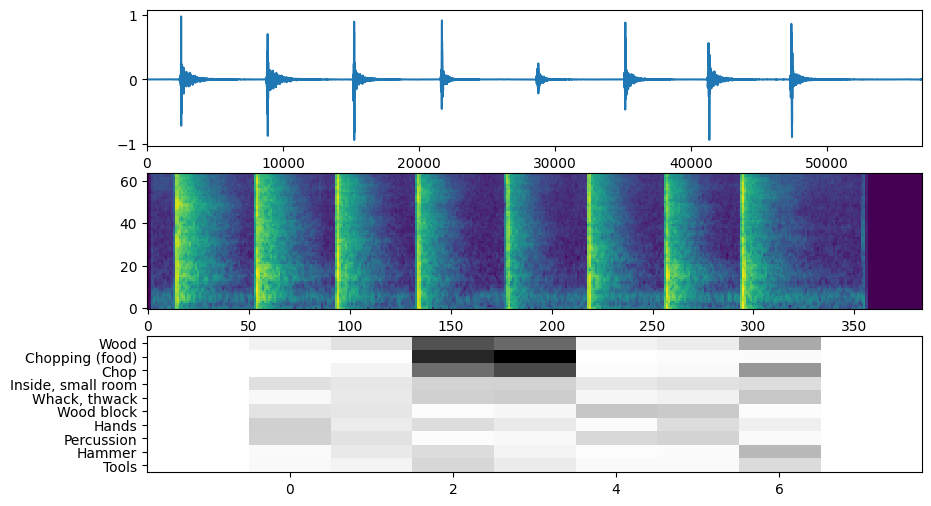

In [14]:
plt.figure(figsize=(10, 6))

# Plot the waveform.
plt.subplot(3, 1, 1)
plt.plot(waveform)
plt.xlim([0, len(waveform)])

# Plot the log-mel spectrogram (returned by the model).
plt.subplot(3, 1, 2)
plt.imshow(spectrogram_np.T, aspect='auto', interpolation='nearest', origin='lower')

# Plot and label the model output scores for the top-scoring classes.
mean_scores = np.mean(scores, axis=0)
top_n = 10
top_class_indices = np.argsort(mean_scores)[::-1][:top_n]
plt.subplot(3, 1, 3)
plt.imshow(scores_np[:, top_class_indices].T, aspect='auto', interpolation='nearest', cmap='gray_r')

# patch_padding = (PATCH_WINDOW_SECONDS / 2) / PATCH_HOP_SECONDS
# values from the model documentation
patch_padding = (0.025 / 2) / 0.01
plt.xlim([-patch_padding-0.5, scores.shape[0] + patch_padding-0.5])
# Label the top_N classes.
yticks = range(0, top_n, 1)
plt.yticks(yticks, [class_names[top_class_indices[x]] for x in yticks])
_ = plt.ylim(-0.5 + np.array([top_n, 0]))

## 4. Batch Classification Testing

**Objective:** Evaluate YAMNet on all 31 smartphone recordings.

**Metrics:**
- Top-1 classification accuracy
- Top-3 classification accuracy
- Consistency across repeated recordings
- Shorter recordings (exploratory; sub-second performance not verified)
- Potential usefulness for assigning musical roles (not quantitatively evaluated)

In [15]:
from pathlib import Path

recordings_dir = Path("/content/yamnet_recordings/wav/")
wav_files = sorted(recordings_dir.glob("*.wav"))
wav_files = [f for f in wav_files if f.name != "keys_01.wav"]
# An earlier individual conversion created an extra keys_01.wav, excluding it to avoid counting that file twice.
print(f"Found {len(wav_files)} WAV files")

Found 31 WAV files


In [16]:
import csv
import numpy as np
import tensorflow as tf
import tensorflow_hub as hub
from scipy.io import wavfile

model = hub.load('https://tfhub.dev/google/yamnet/1')
with tf.io.gfile.GFile(model.class_map_path().numpy()) as f:
    class_names = [row['display_name'] for row in csv.DictReader(f)]
results = []
for wav_path in wav_files:
    sample_rate, wav_data = wavfile.read(str(wav_path))
    waveform = (wav_data / tf.int16.max).astype(np.float32)
    scores, embeddings, spectrogram = model(waveform)
    mean_scores = scores.numpy().mean(axis=0)
    top3 = np.argsort(mean_scores)[::-1][:3]
    results.append([
        wav_path.name,
        round(len(wav_data) / sample_rate, 2),
        class_names[top3[0]], round(float(mean_scores[top3[0]]), 2),
        class_names[top3[1]], round(float(mean_scores[top3[1]]), 2),
        class_names[top3[2]], round(float(mean_scores[top3[2]]), 2),
    ])

    print(wav_path.name)
    for i in top3:
        print(f"  {class_names[i]}: {mean_scores[i]:.2f}")

Bottle_01.wav
  Cowbell: 0.24
  Percussion: 0.19
  Wood block: 0.18
Bottle_02.wav
  Percussion: 0.27
  Musical instrument: 0.20
  Cowbell: 0.17
Bottle_03.wav
  Dishes, pots, and pans: 0.21
  Cutlery, silverware: 0.18
  Percussion: 0.15
Clap_01.wav
  Wood: 0.21
  Chopping (food): 0.21
  Chop: 0.20
Clap_02.wav
  Chop: 0.33
  Wood: 0.29
  Whack, thwack: 0.13
Clap_03.wav
  Inside, small room: 0.23
  Wood: 0.18
  Hands: 0.17
Coins_01.wav
  Rattle (instrument): 0.45
  Maraca: 0.29
  Percussion: 0.26
Coins_02.wav
  Inside, small room: 0.32
  Tearing: 0.28
  Crumpling, crinkling: 0.19
Coins_03.wav
  Rattle (instrument): 0.38
  Music: 0.37
  Maraca: 0.26
Keys_01.wav
  Coin (dropping): 0.63
  Glass: 0.36
  Keys jangling: 0.31
Keys_02.wav
  Crumpling, crinkling: 0.31
  Glass: 0.22
  Chink, clink: 0.20
Keys_03.wav
  Crumpling, crinkling: 0.44
  Tearing: 0.39
  Inside, small room: 0.32
Knock_01.wav
  Knock: 0.75
  Door: 0.45
  Tap: 0.20
Knock_02.wav
  Knock: 0.23
  Wood block: 0.23
  Chopping (food

In [17]:
with open("/content/yamnet_results.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["file", "duration", "top1", "top1_score", "top2", "top2_score", "top3", "top3_score"])
    writer.writerows(results)

In [18]:
durations = [r[1] for r in results]
print(min(durations), max(durations))

1.07 4.35


## 5. Results and Evaluation

### 5.1 Dataset Overview

- **Total recordings:** 31
- **Sound categories:** 10
- **Recording device:** Samsung Galaxy S25
- **Audio preprocessing:** Converted M4A recordings to 16 kHz mono WAV using FFmpeg
- **Classification model:** YAMNet (521 AudioSet classes)
- **Evaluation method:** Top-1 and top-3 predictions using mean scores across audio windows
- **Recording durations:** Ranged from 1.07 to 4.35 seconds.
### 5.2 Classification Results

Preliminary manual evaluation of the 30 standard recordings:

- **Top-1 (7/30):** Knock_01, Knock_02, Paper_01, Paper_02, Snap_02, Zipper_01, Zipper_02.
- **Top-3 (13/30):** The seven above, plus Keys_01, Snap_01, Snap_03, Water_01, Water_02, and Water_03.

All remaining recordings were counted as non-matches. Individual predictions are available in the CSV.

These are preliminary counts based on manually matching predictions to the recorded sounds. The top-3 count includes general labels such as "Water" for pouring-water recordings. Similar-sounding objects, such as "Cowbell" for a metal bottle, were not counted as correct object classifications.

The additional mixed-sound recording, Water_noisy, was evaluated separately.

The prediction scores in the notebook and CSV are average YAMNet class scores across audio frames, not probabilities of a prediction being correct.

### 5.3 Key Observations

**Successful classifications:**
- Finger snapping appeared in the top 2 predictions for all three snap recordings.
- Knocking was correctly identified as "Knock" in two recordings.
- Paper crumpling was correctly identified in two recordings.
- Zipper sounds were correctly identified in two recordings.

**Classification challenges:**
- Keys were often classified as coins or crumpling sounds.
- Clapping was frequently classified as wood or chopping.
- Pen clicking was confused with coins and scissors.
- 2 recordings (Water_03 and Zipper_03) received "Silence" as their top prediction.

**Musical relevance:**
- Metal bottle recordings produced labels such as "Cowbell" and "Percussion".
- Coin recordings sometimes produced labels such as "Rattle (instrument)" and "Maraca".
- These predictions may still be useful for assigning musical roles even when the exact object is incorrectly identified.

Musical-role classification accuracy has not yet been measured.

### 5.4 Consistency Across Repeated Recordings

YAMNet produced the same top-1 prediction across the first two recordings for only 3 out of 10 sound types (30%).

**Consistent predictions:**
- Knocking: Knock → Knock
- Paper: Crumpling, crinkling → Crumpling, crinkling
- Zipper: Zipper (clothing) → Zipper (clothing)

**Examples of inconsistent predictions:**
- Keys: Coin (dropping) → Crumpling, crinkling
- Water: Fill (with liquid) → Drip
- Bottle: Cowbell → Percussion

This suggests that exact-label predictions can vary between recordings of the same sound. However, different labels may still represent similar acoustic properties or musical roles.

Further testing is needed to determine whether these variations affect beat generation.



## 6. Conclusions & Recommendations

### 6.1 Overall Findings

Testing YAMNet on 31 smartphone recordings showed mixed classification performance.

- Exact sound identification was inconsistent, particularly for keys, clapping, and pen clicking.
- Some sounds, including finger snapping, knocking, and paper crumpling, were recognized more reliably.
- Incorrect object predictions sometimes described acoustically similar sounds. For example, a metal water bottle was classified as "Cowbell" or "Percussion".
- The mixed-sound water recording received "Inside, small room" as its top prediction, suggesting potential sensitivity to interfering sounds.

### 6.2 Limitations

- Only 31 recordings were tested, covering 10 sound categories.
- All recordings were collected using one smartphone.
- The recordings were not independently labeled or evaluated by multiple reviewers.
- All short recordings exceeded one second.
- Musical-role classification accuracy was not measured.
- Performance at lower sample rates was not evaluated.

### 6.3 Recommendation

YAMNet is a reasonable baseline for further development, but the results do not support relying on its top prediction alone for accurate object identification.

For Encore, the next steps should be:

1. Map YAMNet predictions to broader musical roles such as hit, ringing/tonal, and texture.
2. Evaluate whether these roles remain consistent across repeated recordings.
3. Allow users to review and correct assigned roles.
4. Investigate alternative classifiers if musical-role accuracy remains insufficient.

### 6.4 Final Assessment

YAMNet successfully processed all 31 recordings and produced usable classification scores. However, its exact-label performance was inconsistent.

Further testing is needed to determine whether its predictions are reliable enough to support automatic sound-role assignment in Encore.
